# 04 · Recommendations: "you might also like"

**Question:** given what a customer has viewed, put in the cart and bought, which 10 perfumes should
the shop show them next?

**Implicit feedback** from the #129 event stream (`marts.fct_events`) and the order lines
(`marts.fct_order_items`): nobody rates perfumes, but a view, a cart add and a purchase are
increasingly strong signals. Items are perfumes (`product_key`), not sizes.

**Models:**

1. *popularity*: the 10 best-selling perfumes, the same for everyone (the baseline);
2. *item-item*: cosine similarity of perfumes that are viewed, carted and bought together (by the
   same customer or in the same anonymous session), scored against the customer's own history;
3. *implicit ALS*: matrix factorisation for implicit feedback (Hu, Koren & Volinsky, 2008).

**Offline evaluation, leave-last-out:** for every customer with at least two different purchased
perfumes, hide the last one, train on everything the customer did *before the visit in which they
bought it* (otherwise the views that led to the purchase would give it away), and check whether the
hidden perfume is in the top 10: Recall@10, NDCG@10 and catalogue coverage.

In [1]:
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from implicit.als import AlternatingLeastSquares
from sklearn.preprocessing import normalize

from jassmin_ml import metrics, plots, splits
from jassmin_ml.db import read_mart
from jassmin_ml.seed import SEED, set_seeds
from jassmin_ml.truth import load_truth

set_seeds()
plots.use_style()
pd.set_option("display.precision", 4)

WEIGHTS = {"product_view": 1.0, "add_to_cart": 3.0, "purchase": 5.0}
LONG_DWELL_MS = 10_000  # a view with at least 10 s on the page counts one extra

## Interactions

In [2]:
events = read_mart(
    """
    with dwell as (
      select session_id, product_key, max(dwell_ms) as dwell_ms
      from marts.fct_events
      where event_type = 'product_dwell'
      group by 1, 2
    )
    select e.customer_key, e.session_id, e.event_type, e.event_at, e.product_key,
      case when e.event_type = 'product_view' then coalesce(d.dwell_ms, 0) else 0 end as dwell_ms
    from marts.fct_events e
    left join dwell d using (session_id, product_key)
    where e.event_type in ('product_view', 'add_to_cart') and e.product_key is not null and e.product_key <> -1
    """
)
events["event_at"] = pd.to_datetime(events["event_at"], utc=True)

orders = read_mart(
    """
    select distinct i.customer_key, i.product_key, o.order_id, o.created_at as event_at
    from marts.fct_order_items i
    join marts.fct_orders o using (order_id)
    where i.is_revenue and i.customer_key is not null and i.product_key <> -1
    """
)
orders["event_at"] = pd.to_datetime(orders["event_at"], utc=True)

# The visit an order was placed in: the customer's latest session that started before the order.
sessions = read_mart(
    "select session_id, customer_key, started_at from marts.fct_sessions where customer_key is not null"
)
sessions["started_at"] = pd.to_datetime(sessions["started_at"], utc=True)
orders = pd.merge_asof(
    orders.sort_values("event_at"),
    sessions.sort_values("started_at"),
    left_on="event_at",
    right_on="started_at",
    by="customer_key",
    direction="backward",
).drop(columns="started_at")
orders["event_type"] = "purchase"
orders["dwell_ms"] = 0

logged_in = pd.concat([events[events["customer_key"].notna()], orders], ignore_index=True)
logged_in["weight"] = logged_in["event_type"].map(WEIGHTS) + (
    (logged_in["event_type"] == "product_view") & (logged_in["dwell_ms"] >= LONG_DWELL_MS)
).astype(float)
anonymous = events[events["customer_key"].isna()]
products = read_mart("select product_key, title, brand, fragrance_family, gender from marts.dim_products where product_key <> -1")
catalog = np.sort(products["product_key"].to_numpy())
item_index = {p: i for i, p in enumerate(catalog)}
print(f"{len(logged_in):,} logged-in interactions by {logged_in['customer_key'].nunique():,} customers; "
      f"{anonymous['session_id'].nunique():,} anonymous sessions; {len(catalog)} perfumes")

171,975 logged-in interactions by 10,258 customers; 34,696 anonymous sessions; 128 perfumes


## Leave-last-out split

The same split is applied twice: once for the test (the last purchased perfume), and once more on
the training data for a validation fold (the one before it), used only to tune ALS.

In [3]:
purchases = orders[["customer_key", "product_key", "event_at", "session_id"]]
train_interactions, test_targets = splits.leave_last_out(purchases, logged_in)
train_purchases = train_interactions[train_interactions["event_type"] == "purchase"]
fit_interactions, validation_targets = splits.leave_last_out(
    train_purchases[["customer_key", "product_key", "event_at", "session_id"]], train_interactions
)


def with_history(targets: pd.Series, interactions: pd.DataFrame) -> pd.Series:
    """Only customers with something left to learn from. Those whose every interaction was in the
    held-out visit are cold-start: popularity is all any model could offer them, so they're left out
    of the comparison."""
    return targets[targets.index.isin(interactions["customer_key"].unique())]


all_test = len(test_targets)
test_targets = with_history(test_targets, train_interactions)
validation_targets = with_history(validation_targets, fit_interactions)
print(f"test users: {len(test_targets):,} (of {all_test:,}; the rest have no history before the held-out visit); "
      f"validation users: {len(validation_targets):,}")

test users: 3,512 (of 6,233; the rest have no history before the held-out visit); validation users: 1,747


The customers left out are those whose two or more perfumes were all bought **in a single order**,
such as the tester trio (three 10 ml samples) or the couple offer, and who had no other visit before
it. Hiding one perfume of that order also hides the visit, so nothing is left to learn from. In
production they are a cold-start case, served by popularity or by the other perfumes in the cart.

## Models

In [4]:
def user_item_matrix(interactions: pd.DataFrame) -> tuple[sp.csr_matrix, dict[str, int]]:
    """Summed weights per (customer, perfume), log-damped so a perfume viewed 30 times doesn't drown
    out a purchase."""
    users = {u: i for i, u in enumerate(sorted(interactions["customer_key"].unique()))}
    summed = interactions.groupby(["customer_key", "product_key"])["weight"].sum().reset_index()
    matrix = sp.csr_matrix(
        (
            np.log1p(summed["weight"].to_numpy()),
            (summed["customer_key"].map(users).to_numpy(), summed["product_key"].map(item_index).to_numpy()),
        ),
        shape=(len(users), len(catalog)),
    )
    return matrix, users


def popularity(interactions: pd.DataFrame, k: int = 10) -> list[int]:
    counts = interactions[interactions["event_type"] == "purchase"]["product_key"].value_counts()
    return counts.index[:k].tolist()


def item_similarity(user_items: sp.csr_matrix) -> np.ndarray:
    """Cosine similarity of perfumes over customers' histories and anonymous sessions."""
    session_items = (
        anonymous.assign(item=anonymous["product_key"].map(item_index))
        .drop_duplicates(["session_id", "item"])
    )
    session_ids = {s: i for i, s in enumerate(session_items["session_id"].unique())}
    sessions_matrix = sp.csr_matrix(
        (np.ones(len(session_items)), (session_items["session_id"].map(session_ids), session_items["item"])),
        shape=(len(session_ids), len(catalog)),
    )
    stacked = sp.vstack([user_items, sessions_matrix]).tocsc()
    columns = normalize(stacked, axis=0)
    similarity = (columns.T @ columns).toarray()
    np.fill_diagonal(similarity, 0.0)
    return similarity


def recommend_item_item(similarity: np.ndarray, user_items: sp.csr_matrix, k: int = 10) -> np.ndarray:
    scores = user_items @ similarity
    scores = np.asarray(scores)
    # A perfume the customer already likes is a fair recommendation too (repeat purchases are real),
    # so it keeps its own weight as a score.
    scores = scores + user_items.toarray()
    return np.argsort(-scores, axis=1, kind="stable")[:, :k]


def fit_als(user_items: sp.csr_matrix, factors: int, regularization: float, alpha: float) -> AlternatingLeastSquares:
    model = AlternatingLeastSquares(
        factors=factors, regularization=regularization, alpha=alpha, iterations=30,
        random_state=SEED, num_threads=1, calculate_training_loss=False,
    )  # fmt: skip
    model.fit(user_items, show_progress=False)
    return model


def recommend_als(model: AlternatingLeastSquares, user_items: sp.csr_matrix, k: int = 10) -> np.ndarray:
    ids, _ = model.recommend(
        np.arange(user_items.shape[0]), user_items, N=k, filter_already_liked_items=False
    )
    return ids


def evaluate(recommended: np.ndarray, users: dict[str, int], targets: pd.Series, k: int = 10) -> dict[str, float]:
    lists = {u: [catalog[i] for i in recommended[users[u]]] for u in targets.index}
    return metrics.ranking_report(lists, targets.to_dict(), len(catalog), k)

### Tuning ALS on the validation fold

In [5]:
fit_matrix, fit_users = user_item_matrix(fit_interactions)
grid = []
for factors in (16, 32, 64):
    for regularization in (0.05, 0.5):
        for alpha in (1.0, 10.0):
            model = fit_als(fit_matrix, factors, regularization, alpha)
            score = evaluate(recommend_als(model, fit_matrix), fit_users, validation_targets)
            grid.append({"factors": factors, "regularization": regularization, "alpha": alpha, **score})
grid = pd.DataFrame(grid).sort_values("ndcg@10", ascending=False)
best = grid.iloc[0]
grid.head(6)

,factors,regularization,alpha,recall@10,ndcg@10,coverage@10
2,16,0.50,1.0,0.5197,0.2878,0.6719
0,16,0.05,1.0,0.5175,0.2863,0.6719
9,64,0.05,10.0,0.4991,0.2862,1.0000
6,32,0.50,1.0,0.5318,0.2838,0.9219
4,32,0.05,1.0,0.5312,0.2834,0.9062
5,32,0.05,10.0,0.5123,0.2810,1.0000


### Test

In [6]:
train_matrix, train_users = user_item_matrix(train_interactions)
popular = popularity(train_interactions)
recommendations = {
    "popularity": np.tile([item_index[p] for p in popular], (train_matrix.shape[0], 1)),
    "item-item (cosine)": recommend_item_item(item_similarity(train_matrix), train_matrix),
    "implicit ALS": recommend_als(
        fit_als(train_matrix, int(best["factors"]), best["regularization"], best["alpha"]), train_matrix
    ),
}
results = pd.DataFrame({name: evaluate(rec, train_users, test_targets) for name, rec in recommendations.items()}).T
results

,recall@10,ndcg@10,coverage@10
popularity,0.2275,0.1033,0.0781
item-item (cosine),0.5461,0.3351,1.0000
implicit ALS,0.5191,0.2920,0.7188


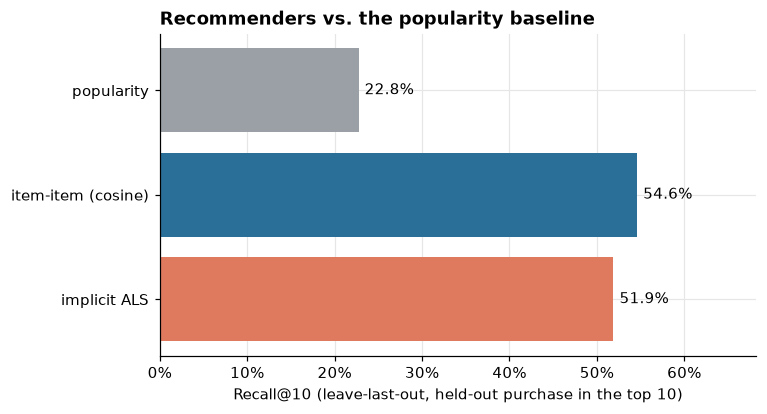

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.8))
colors = [plots.MUTED, plots.ACCENT, plots.PALETTE[1]]
bars = ax.barh(results.index[::-1], results["recall@10"][::-1], color=colors[::-1])
ax.bar_label(bars, labels=[f"{v:.1%}" for v in results["recall@10"][::-1]], padding=4)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Recall@10 (leave-last-out, held-out purchase in the top 10)")
ax.set_title("Recommenders vs. the popularity baseline")
ax.set_xlim(0, results["recall@10"].max() * 1.25)
plots.save_figure(fig, "04_recall_at_10")
plt.show()

Both personalised models more than double the popularity baseline's Recall@10 and cover most of the
catalogue, where popularity only ever shows the same 10 perfumes. The simple **item-item cosine**
model wins on both Recall@10 and NDCG@10. With 128 perfumes and tens of thousands of anonymous
sessions, co-viewing is a dense, reliable signal, and ALS's extra flexibility doesn't pay off. It is
also the easiest model to serve: a 128 × 128 similarity table.

## Did the models learn the planted taste?

The generator gives every customer a favourite fragrance family, and 65 % of their views are in it.
The share of each model's top 10 in the customer's *true* favourite family (from the ground truth,
used only for this check):

In [8]:
truth = load_truth().set_index("customer_key")
family_of = products.set_index("product_key")["fragrance_family"]
favourite = truth["favourite_family"].reindex(test_targets.index)
evaluable = favourite.dropna().index
taste = {}
for name, rec in recommendations.items():
    shares = [
        np.mean([family_of.get(catalog[i]) == favourite[u] for i in rec[train_users[u]]]) for u in evaluable
    ]
    taste[name] = np.mean(shares)
taste["(random perfume)"] = float((family_of.value_counts(normalize=True) * favourite.value_counts(normalize=True)).sum())
pd.Series(taste, name="share of top 10 in the customer's favourite family").to_frame()

,share of top 10 in the customer's favourite family
popularity,0.0618
item-item (cosine),0.1605
implicit ALS,0.1683
(random perfume),0.0612


Popularity is no better than picking perfumes at random, while both personalised models put almost
three times as many perfumes from the customer's true favourite family in the top 10. They learned
the planted taste from behaviour alone. (Most of the catalogue is in two or three big families, so
16–17 % is far from the 65 % view share: the top 10 also follows co-views across families.)

## A note on position bias

The `/popular` list, the catalogue and the home page show perfumes in a fixed order, and #129
records each impression's `list_position`. The naive click-through rate by position is misleading
here for two reasons, both visible in the data:

1. **Impressions are logged on visibility** (a card on screen for at least a second). Most visitors
   see only the first 2–6 cards, so a deeper card gets an impression mostly when the visitor
   scrolls to it *to click it*. Beyond the first screen the CTR is close to 100 % by construction,
   so the table shows positions 1–6 separately and everything deeper as one row.
2. **Position is confounded with the item.** `/popular` is sorted by popularity, so its top slots
   hold the perfumes people want anyway. A CTR spike at one position is that perfume's appeal, not
   the slot's.

In [9]:
listing = read_mart(
    """
    select list_id, list_position::int as position,
      count(*) filter (where event_type = 'product_impression') as impressions,
      count(*) filter (where event_type = 'product_click') as clicks
    from marts.fct_events
    where event_type in ('product_impression', 'product_click') and list_id is not null
    group by 1, 2
    """
)
listing["ctr"] = listing["clicks"] / listing["impressions"]
first_screen = listing[listing["position"] <= 6].pivot_table(index="position", columns="list_id", values="ctr")
deeper = (
    listing[listing["position"] > 6].groupby("list_id")[["impressions", "clicks"]].sum()
    .assign(ctr=lambda t: t["clicks"] / t["impressions"])["ctr"].rename("positions 7+")
)
pd.concat([first_screen, deeper.to_frame().T])

list_id,catalog,home,offers,popular,search
1,0.0590,0.0861,0.0190,0.0845,0.6908
2,0.0324,0.3016,0.0320,0.2909,0.3392
3,0.0608,0.0381,0.0638,0.0377,0.3951
4,0.0268,0.0146,0.1455,0.0093,0.2937
5,0.0562,0.0351,0.2511,0.0315,0.1990
6,0.1439,0.2357,0.1041,0.2526,0.3398
positions 7+,1.2116,1.0135,1.1011,1.0737,1.1641


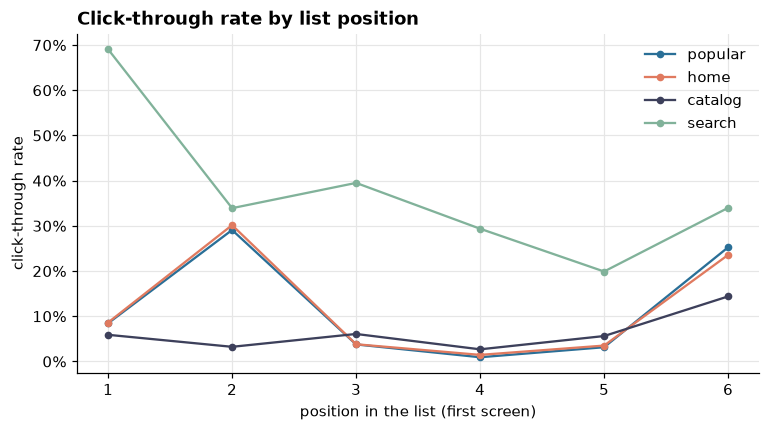

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
for list_id, color in zip(["popular", "home", "catalog", "search"], plots.PALETTE):
    rows = listing[(listing["list_id"] == list_id) & (listing["position"] <= 6)]
    ax.plot(rows["position"], rows["ctr"], marker="o", ms=4, color=color, label=list_id)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("position in the list (first screen)")
ax.set_ylabel("click-through rate")
ax.set_title("Click-through rate by list position")
ax.legend()
plt.show()

The `/popular` and home lists both spike at position 2, where their most wanted perfume sits, while
the catalogue, which isn't sorted by popularity, stays at 3–6 %. Position 6 is already inflated in
every list: it is on screen only for the visitors who scroll furthest, so the logging artefact of
point 1 starts there. Search results have a far higher CTR (the visitor has filtered for what they
want) that falls with position. That is the shape a real position effect would have, but here the
small filtered result sets produce it too, and this data can't tell the two apart.

**Why it matters for the recommender.** The popularity baseline counts purchases, and purchases
partly follow what the shop's own lists put in front of people: a feedback loop that makes popular
perfumes look more popular. Before relying on clicks as training signal, the shop should
(a) log impressions for the whole list it renders, not only the visible cards, and (b) occasionally
randomise the top slots (or interleave two rankings), so that position and appeal can be separated
and clicks reweighted by inverse propensity.

## Checks

In [11]:
popularity_recall = results.loc["popularity", "recall@10"]
best_model = results["recall@10"].drop("popularity").idxmax()
print(f"Recall@10: popularity {popularity_recall:.3f}, best {best_model} {results.loc[best_model, 'recall@10']:.3f}")
assert results.loc[best_model, "recall@10"] > popularity_recall, "a recommender should beat popularity on Recall@10"
assert results.loc[best_model, "coverage@10"] > results.loc["popularity", "coverage@10"]
print("04 checks passed")

Recall@10: popularity 0.228, best item-item (cosine) 0.546
04 checks passed
